# Atividade 12 - Exploracao complementar com agrupamento (Encontro 12)

Projeto: recomendacao de treinos personalizados em academia.

Ate aqui todo o projeto foi supervisionado: a Arvore de Decisao (`max_depth=5`) aprende a prever `treino_recomendado` (Treino A, B, C ou D). Nesta atividade a pergunta muda: **existe, nos perfis dos alunos, uma estrutura que ninguem rotulou e que ajuda a entender onde o modelo falha?**

**Caminho escolhido: A (agrupamento com K-means)**, cruzando os grupos encontrados com o acerto e o erro do modelo.

**Etapa:** entrega unica (Atividade 12 nao tem esboco).

In [1]:
import os
if not os.path.exists('dataset_academia_tratado.csv'):
    !git clone https://github.com/Vinicasagrande87/fundamentos_ia.git
    %cd fundamentos_ia

## 1. Justificativa do caminho escolhido (A - agrupamento)

- A base e **tabular**, com 300 alunos (acima do limite de 100 linhas em que o agrupamento ficaria fragil demais) e com variaveis que descrevem o comportamento/perfil do aluno: idade, dias disponiveis, nivel, acesso a equipamento, restricao fisica e objetivo.
- O projeto e de **classificacao**, e ja sabemos (Atividades 10 e 11) que o ponto fraco do modelo e o **recall de Treino D** (falso negativo = recomendar treino mais intenso do que o indicado para quem tem restricao, pouco equipamento ou pouca experiencia). A pergunta util nao e "quais tipos de aluno existem", e sim **"os erros do modelo se concentram em algum tipo de aluno?"**. Isso e exatamente a orientacao para classificacao tabular: agrupar as entidades por comportamento e cruzar com acerto/erro.
- Agrupar **somente os erros** foi descartado: no split de teste da Atividade 10 ha apenas 6 erros, numero pequeno demais para formar grupos. Por isso agrupamos todos os 300 alunos e usamos previsoes de validacao cruzada (cada aluno e previsto por um modelo que nao o viu no treino), o que da um "acertou/errou" honesto para a base inteira.
- O caminho B (exploratoria) continua aparecendo como verificacao na secao 10, para conferir se o K-means deixou passar algum padrao.

## 2. Carregamento e erro do modelo em cada aluno

Mesmo modelo das Atividades 9-11 (`DecisionTreeClassifier(max_depth=5, random_state=42)`), mesma codificacao e mesma validacao cruzada (`cv=5`) da secao 13 da Atividade 10. `cross_val_predict` devolve, para cada aluno, a previsao feita pelo fold em que ele estava no teste.

Tambem reaplicamos a regra de geracao (`recomenda_treino`, de `gerar_dataset.py`) para separar dois tipos de erro:
- **erro por ruido**: o rotulo da base contradiz a propria regra (8% de ruido proposital) - nenhum modelo deveria "acertar" esses casos;
- **erro real do modelo**: o rotulo esta coerente com a regra e mesmo assim o modelo errou - esse e o erro que interessa.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from gerar_dataset import recomenda_treino

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

In [3]:
df = pd.read_csv('dataset_academia_tratado.csv')

X = df.drop(columns=['aluno_id', 'treino_recomendado'])
y = df['treino_recomendado']
X = pd.get_dummies(X, columns=['objetivo', 'nivel_experiencia', 'restricao_fisica', 'equipamento_disponivel'], drop_first=False)

modelo = DecisionTreeClassifier(max_depth=5, random_state=42)
df['previsto'] = cross_val_predict(modelo, X, y, cv=5)
df['erro'] = (df['previsto'] != y).astype(int)

df['regra'] = [
    recomenda_treino(r.objetivo, r.nivel_experiencia, r.dias_disponiveis_semana, r.restricao_fisica, r.equipamento_disponivel)
    for r in df.itertuples()
]
df['ruido'] = (df['regra'] != y).astype(int)
df['erro_real'] = ((df['erro'] == 1) & (df['ruido'] == 0)).astype(int)

print('Alunos:', len(df))
print('Acuracia da validacao cruzada (deve bater com 0,8267 da Atividade 10):', round(1 - df['erro'].mean(), 4))
print('Erros do modelo:', df['erro'].sum())
print('  - erros em registros com ruido de rotulo:', (df['erro'] & df['ruido']).sum(), 'de', df['ruido'].sum(), 'registros ruidosos')
print('  - erros reais (rotulo coerente com a regra):', df['erro_real'].sum())

Alunos: 300
Acuracia da validacao cruzada (deve bater com 0,8267 da Atividade 10): 0.8267
Erros do modelo: 52
  - erros em registros com ruido de rotulo: 24 de 24 registros ruidosos
  - erros reais (rotulo coerente com a regra): 28


## 3. Variaveis usadas no agrupamento

| Variavel no agrupamento | Origem | Codificacao | Por que entra |
|---|---|---|---|
| `idade` | idade | numerica | perfil do aluno; a Atividade 10 mostrou que a arvore usa idade como atalho |
| `dias_disponiveis_semana` | dias | numerica | define volume possivel de treino |
| `nivel_ord` | nivel_experiencia | ordinal 0 = Iniciante, 1 = Intermediario, 2 = Avancado | tem ordem natural de progressao |
| `acesso_equip` | equipamento_disponivel | ordinal 0 = Nenhum, 1 = Limitado, 2 = Completo | tem ordem natural de acesso |
| `tem_restricao` | restricao_fisica | binaria 0/1 | o que importa para a seguranca e *ter ou nao* restricao; separar Joelho/Ombro/Lombar criaria 3 colunas raras (24-34 alunos) que dominariam a distancia |
| `obj_*` (3 colunas) | objetivo | one-hot | nominal, sem ordem - nao pode virar 0/1/2 |

**Removidos:**
- `aluno_id` - identificador, nao descreve comportamento (distancia entre ids nao significa nada);
- `treino_recomendado` - e a resposta; se entrasse, o K-means so redescobriria o rotulo e a analise deixaria de ser nao supervisionada;
- `previsto`, `erro`, `ruido`, `regra` - sao usados **depois**, so para cruzar com os grupos, nunca para forma-los.

In [4]:
feat = pd.DataFrame({
    'idade': df['idade'],
    'dias_disponiveis_semana': df['dias_disponiveis_semana'],
    'nivel_ord': df['nivel_experiencia'].map({'Iniciante': 0, 'Intermediario': 1, 'Avancado': 2}),
    'acesso_equip': df['equipamento_disponivel'].map({'Nenhum': 0, 'Limitado': 1, 'Completo': 2}),
    'tem_restricao': (df['restricao_fisica'] != 'Nenhuma').astype(int),
})
for o in ['Emagrecimento', 'Hipertrofia', 'Condicionamento']:
    feat['obj_' + o] = (df['objetivo'] == o).astype(int)

assert 'aluno_id' not in feat.columns and 'treino_recomendado' not in feat.columns
assert feat.isna().sum().sum() == 0
print('Colunas usadas no agrupamento:', list(feat.columns))
feat.head()

Colunas usadas no agrupamento: ['idade', 'dias_disponiveis_semana', 'nivel_ord', 'acesso_equip', 'tem_restricao', 'obj_Emagrecimento', 'obj_Hipertrofia', 'obj_Condicionamento']


,idade,dias_disponiveis_semana,nivel_ord,acesso_equip,tem_restricao,obj_Emagrecimento,obj_Hipertrofia,obj_Condicionamento
0,32,2,2,2,0,0,0,1
1,37,4,0,2,0,0,1,0
2,24,3,0,1,1,0,0,1
3,31,4,0,0,1,1,0,0
4,22,3,1,2,0,0,0,1


## 4. Padronizacao (StandardScaler)

O K-means agrupa por distancia. Sem padronizar, `idade` (16 a 51, desvio ~7,7) dominaria a distancia sobre `tem_restricao` (0 ou 1) so por causa da escala. Depois do `StandardScaler` todas as colunas ficam com media 0 e desvio 1.

In [5]:
scaler = StandardScaler()
Z = scaler.fit_transform(feat)

comparacao = pd.DataFrame({
    'desvio_antes': feat.std(ddof=0).round(2),
    'media_depois': Z.mean(axis=0).round(2),
    'desvio_depois': Z.std(axis=0).round(2),
})
comparacao

,desvio_antes,media_depois,desvio_depois
idade,7.70,0.0,1.0
dias_disponiveis_semana,1.27,0.0,1.0
nivel_ord,0.71,-0.0,1.0
acesso_equip,0.63,0.0,1.0
tem_restricao,0.46,0.0,1.0
obj_Emagrecimento,0.47,0.0,1.0
obj_Hipertrofia,0.49,-0.0,1.0
obj_Condicionamento,0.45,0.0,1.0


## 5. Escolha do numero de grupos (cotovelo + silhueta)

Testamos k = 2 a 8. Inercia = soma das distancias de cada aluno ao centro do seu grupo (quanto menor, mais compactos); silhueta = o quanto cada aluno esta mais perto do proprio grupo do que do grupo vizinho (-1 a 1, quanto maior melhor).

 k  inercia  silhueta
 2   1930.5     0.202
 3   1488.3     0.294
 4   1372.6     0.257
 5   1259.7     0.241
 6   1183.3     0.222
 7   1120.3     0.216
 8   1055.9     0.213


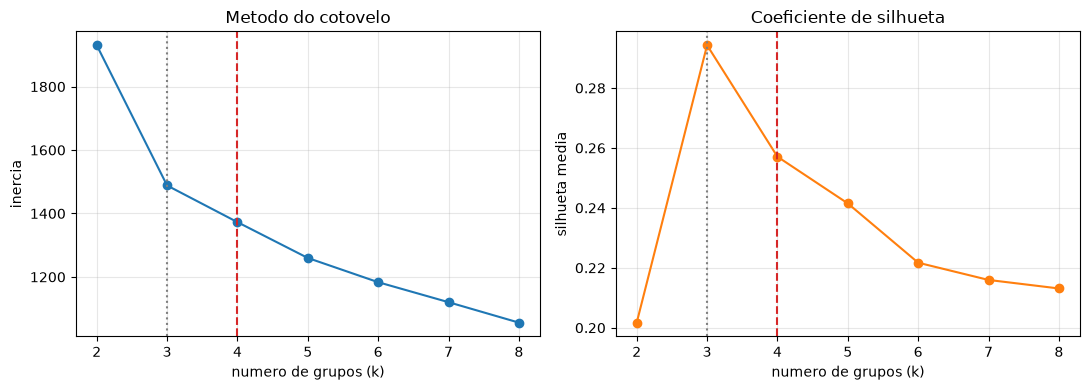

In [6]:
ks = range(2, 9)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(Z, km.labels_))

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 1), 'silhueta': np.round(silhuetas, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inercias, marker='o')
axes[0].set_title('Metodo do cotovelo')
axes[0].set_xlabel('numero de grupos (k)')
axes[0].set_ylabel('inercia')
axes[1].plot(list(ks), silhuetas, marker='o', color='tab:orange')
axes[1].set_title('Coeficiente de silhueta')
axes[1].set_xlabel('numero de grupos (k)')
axes[1].set_ylabel('silhueta media')
for ax in axes:
    ax.axvline(3, ls=':', color='gray')
    ax.axvline(4, ls='--', color='tab:red')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('cotovelo_silhueta_atividade12.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# O que o k=3 (o melhor pela silhueta) separa?
km3 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(Z)
print('k=3 - grupos x objetivo:')
print(pd.crosstab(km3.labels_, df['objetivo']))

k=3 - grupos x objetivo:
objetivo  Condicionamento  Emagrecimento  Hipertrofia
row_0                                                
0                       0              0          114
1                      83              0            0
2                       0            103            0


**Leitura e decisao:**

- O cotovelo mais nitido e em **k=3** (a inercia cai ~440 de k=2 para k=3 e depois so entre ~60 e ~115 por grupo extra), e a silhueta tambem e maxima em k=3 (0,294).
- Mas o k=3 e **trivial**: a tabela acima mostra que os 3 grupos sao exatamente os 3 objetivos (Hipertrofia, Emagrecimento, Condicionamento). Isso nao e descoberta nenhuma, so reproduz uma coluna que ja existe - acontece porque as 3 colunas one-hot de objetivo sao as maiores distancias da base padronizada.
- **Escolhemos k=4.** A silhueta cai pouco (0,294 -> 0,257, ainda a segunda melhor da faixa e acima de todos os k >= 5), e o 4o grupo e o primeiro que **corta um objetivo por uma variavel de comportamento** (restricao fisica, ver secao 7). k >= 5 so piora a silhueta e cria grupos pequenos (34-43 alunos) sem ganho de interpretacao.
- Ou seja: o numero vem da evidencia (cotovelo/silhueta apontam 3-4) combinada com um argumento do problema (k=3 so repete o objetivo; k=4 e o menor k que diz algo novo).

## 6. K-means com k=4 e estabilidade

Antes de interpretar, verificamos se os grupos sao estaveis: rodamos o K-means com 10 sementes diferentes e comparamos com o resultado de referencia pelo indice de Rand ajustado (ARI = 1 significa particao identica).

In [8]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Z)
rotulos = kmeans.labels_

ari = [adjusted_rand_score(rotulos, KMeans(n_clusters=K, n_init=20, random_state=s).fit_predict(Z)) for s in range(10)]
print('ARI contra 10 sementes diferentes:', np.round(ari, 3))
print('Silhueta com k=4:', round(silhouette_score(Z, rotulos), 3))

ARI contra 10 sementes diferentes: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Silhueta com k=4: 0.257


Os grupos sao numerados pelo algoritmo (0 a 3) e essa numeracao pode mudar entre versoes do scikit-learn. Para que os nomes fiquem sempre no grupo certo, o nome e atribuido pelo **perfil** do grupo (objetivo predominante + proporcao com restricao), nao pelo numero.

In [9]:
def nomeia_grupo(sub):
    obj = sub['objetivo'].mode()[0]
    restr = (sub['restricao_fisica'] != 'Nenhuma').mean()
    if obj == 'Hipertrofia':
        return 'Foco em massa muscular'
    if obj == 'Condicionamento':
        return 'Condicionamento geral'
    if restr > 0.5:
        return 'Emagrecimento com limitacao fisica'
    return 'Emagrecimento sem limitacao'

df['grupo_num'] = rotulos
nomes = {g: nomeia_grupo(df[df['grupo_num'] == g]) for g in range(K)}
df['grupo'] = df['grupo_num'].map(nomes)
assert len(set(nomes.values())) == K, nomes

ordem = ['Foco em massa muscular', 'Emagrecimento sem limitacao', 'Emagrecimento com limitacao fisica', 'Condicionamento geral']
print(nomes)
print(df['grupo'].value_counts().reindex(ordem))

{0: 'Foco em massa muscular', 1: 'Emagrecimento sem limitacao', 2: 'Emagrecimento com limitacao fisica', 3: 'Condicionamento geral'}
grupo
Foco em massa muscular                114
Emagrecimento sem limitacao            67
Emagrecimento com limitacao fisica     36
Condicionamento geral                  83
Name: count, dtype: int64


## 7. Tabela de perfis (media de cada variavel por grupo x media geral)

Valores nas escalas originais (antes da padronizacao), para serem legiveis. `nivel_ord` vai de 0 (Iniciante) a 2 (Avancado); `acesso_equip` de 0 (Nenhum) a 2 (Completo); `tem_restricao` e `obj_*` sao proporcoes.

In [10]:
perfil = feat.copy()
perfil['grupo'] = df['grupo']
tabela = perfil.groupby('grupo').mean().reindex(ordem)
tabela.loc['MEDIA GERAL'] = feat.mean()
tabela['n_alunos'] = list(df['grupo'].value_counts().reindex(ordem)) + [len(df)]
tabela.round(2)

,idade,dias_disponiveis_semana,nivel_ord,acesso_equip,tem_restricao,obj_Emagrecimento,obj_Hipertrofia,obj_Condicionamento,n_alunos
grupo,,,,,,,,,
Foco em massa muscular,29.73,3.52,0.61,1.54,0.30,0.00,1.00,0.00,114
Emagrecimento sem limitacao,27.78,3.31,0.55,1.58,0.00,1.00,0.00,0.00,67
Emagrecimento com limitacao fisica,28.64,3.53,0.42,1.33,1.00,1.00,0.00,0.00,36
Condicionamento geral,30.18,3.40,0.67,1.40,0.27,0.00,0.00,1.00,83
MEDIA GERAL,29.29,3.44,0.59,1.49,0.31,0.34,0.38,0.28,300


In [11]:
# Diferenca de cada grupo em relacao a media geral, em desvios padrao (z).
# |z| >= 0,5 e o que realmente distingue o grupo.
z_grupo = pd.DataFrame(Z, columns=feat.columns).groupby(df['grupo']).mean().reindex(ordem)
z_grupo.round(2)

,idade,dias_disponiveis_semana,nivel_ord,acesso_equip,tem_restricao,obj_Emagrecimento,obj_Hipertrofia,obj_Condicionamento
grupo,,,,,,,,
Foco em massa muscular,0.06,0.06,0.03,0.09,-0.02,-0.72,1.28,-0.62
Emagrecimento sem limitacao,-0.20,-0.10,-0.06,0.15,-0.67,1.38,-0.78,-0.62
Emagrecimento com limitacao fisica,-0.08,0.07,-0.25,-0.24,1.50,1.38,-0.78,-0.62
Condicionamento geral,0.12,-0.03,0.11,-0.14,-0.09,-0.72,-0.78,1.62


In [12]:
print('Treino recomendado (rotulo) por grupo:')
print(pd.crosstab(df['grupo'], df['treino_recomendado']).reindex(ordem))
print()
print('Restricao fisica detalhada por grupo:')
print(pd.crosstab(df['grupo'], df['restricao_fisica']).reindex(ordem))
print()
print('Nivel de experiencia por grupo:')
print(pd.crosstab(df['grupo'], df['nivel_experiencia']).reindex(ordem))

Treino recomendado (rotulo) por grupo:
treino_recomendado                  Treino A  Treino B  Treino C  Treino D
grupo                                                                     
Foco em massa muscular                    64         2        20        28
Emagrecimento sem limitacao                1        42         3        21
Emagrecimento com limitacao fisica         3         9         0        24
Condicionamento geral                      6         1        57        19

Restricao fisica detalhada por grupo:
restricao_fisica                    Joelho  Lombar  Nenhuma  Ombro
grupo                                                             
Foco em massa muscular                  13      12       80      9
Emagrecimento sem limitacao              0       0       67      0
Emagrecimento com limitacao fisica      17      11        0      8
Condicionamento geral                    4      11       61      7

Nivel de experiencia por grupo:
nivel_experiencia                   A

**Nome e caracterizacao de cada grupo:**

| Grupo | Alunos | O que distingue (alem do objetivo) | Treino mais comum |
|---|---|---|---|
| **Foco em massa muscular** | 114 (38%) | Todos com objetivo hipertrofia; restricao (30%) e equipamento (1,54) praticamente na media geral | Treino A (64), mas 28 em Treino D |
| **Emagrecimento sem limitacao** | 67 (22%) | Ninguem com restricao (0% vs 31% na base); os mais jovens (27,8 anos) e com maior acesso a equipamento (1,58) | Treino B (42) |
| **Emagrecimento com limitacao fisica** | 36 (12%) | **Todos** com restricao fisica (joelho 17, lombar 11, ombro 8); os menos experientes (nivel 0,42 vs 0,59) e com o **menor acesso a equipamento** (1,33 vs 1,49) | Treino D (24) |
| **Condicionamento geral** | 83 (28%) | Todos com objetivo condicionamento; ligeiramente mais velhos (30,2) e mais experientes (0,67) | Treino C (57) |

O grupo "Emagrecimento com limitacao fisica" e o unico que se distingue por **mais de uma variavel ao mesmo tempo** (restricao +1,50 desvio padrao acima da media, nivel -0,25 e acesso a equipamento -0,24), e nao so pelo objetivo.

## 8. Cruzamento dos grupos com o acerto e o erro do modelo

Aqui esta a pergunta central da atividade: os erros do modelo se espalham por igual, ou se concentram em algum grupo?

In [13]:
cruz = df.groupby('grupo').agg(
    alunos=('erro', 'size'),
    erros=('erro', 'sum'),
    taxa_erro=('erro', 'mean'),
    erros_por_ruido=('ruido', lambda s: int((s & df.loc[s.index, 'erro']).sum())),
    erros_reais=('erro_real', 'sum'),
    taxa_erro_real=('erro_real', 'mean'),
).reindex(ordem)
cruz.loc['TOTAL'] = [len(df), df['erro'].sum(), df['erro'].mean(), (df['erro'] & df['ruido']).sum(), df['erro_real'].sum(), df['erro_real'].mean()]
cruz['participacao_nos_erros_reais'] = cruz['erros_reais'] / df['erro_real'].sum()
cruz.round(3)

,alunos,erros,taxa_erro,erros_por_ruido,erros_reais,taxa_erro_real,participacao_nos_erros_reais
grupo,,,,,,,
Foco em massa muscular,114.0,19.0,0.167,6.0,13.0,0.114,0.464
Emagrecimento sem limitacao,67.0,8.0,0.119,6.0,2.0,0.030,0.071
Emagrecimento com limitacao fisica,36.0,14.0,0.389,5.0,9.0,0.250,0.321
Condicionamento geral,83.0,11.0,0.133,7.0,4.0,0.048,0.143
TOTAL,300.0,52.0,0.173,24.0,28.0,0.093,1.000


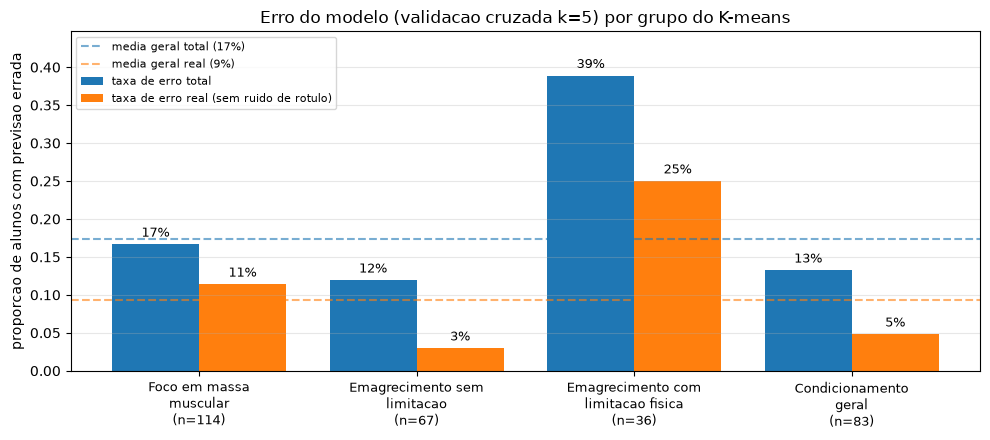

In [14]:
taxa = cruz.loc[ordem, 'taxa_erro']
taxa_real = cruz.loc[ordem, 'taxa_erro_real']
import textwrap
rotulos_eixo = [textwrap.fill(g, 20) + f'\n(n={n})' for g, n in zip(ordem, cruz.loc[ordem, 'alunos'].astype(int))]

fig, ax = plt.subplots(figsize=(10, 4.5))
xpos = np.arange(len(ordem))
ax.bar(xpos - 0.2, taxa, width=0.4, label='taxa de erro total')
ax.bar(xpos + 0.2, taxa_real, width=0.4, label='taxa de erro real (sem ruido de rotulo)')
ax.axhline(df['erro'].mean(), ls='--', color='tab:blue', alpha=0.6, label=f'media geral total ({df.erro.mean():.0%})')
ax.axhline(df['erro_real'].mean(), ls='--', color='tab:orange', alpha=0.6, label=f'media geral real ({df.erro_real.mean():.0%})')
for i, (a, b) in enumerate(zip(taxa, taxa_real)):
    ax.text(i - 0.2, a + 0.01, f'{a:.0%}', ha='center', fontsize=9)
    ax.text(i + 0.2, b + 0.01, f'{b:.0%}', ha='center', fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(rotulos_eixo, fontsize=9)
ax.set_ylim(0, taxa.max() * 1.15)
ax.set_ylabel('proporcao de alunos com previsao errada')
ax.set_title('Erro do modelo (validacao cruzada k=5) por grupo do K-means')
ax.legend(fontsize=8, loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('erro_por_grupo_atividade12.png', dpi=150, bbox_inches='tight')
plt.show()

**Leitura:** o grupo **Emagrecimento com limitacao fisica** tem 12% dos alunos, mas concentra a maior taxa de erro da base: 39% dos alunos dele recebem a previsao errada, mais que o dobro da media (17%). Descontando o ruido de rotulo, a diferenca fica ainda maior: 25% de erro real contra 9% na media, e esse grupo de 36 alunos responde sozinho por **9 dos 28 erros reais (32%)**. Os outros grupos ficam abaixo da media ou perto dela. "Foco em massa muscular" fica um pouco acima (11% de erro real) e, por ser o maior grupo, soma 13 erros reais, mas espalhados por varios tipos de perfil e sem uma direcao dominante. Emagrecimento sem limitacao (3%) e Condicionamento geral (5%) quase nao tem erro real.

## 9. Zoom no ponto cego: que tipo de erro acontece no grupo?

In [15]:
ponto_cego = df[df['grupo'] == 'Emagrecimento com limitacao fisica']
print('Real (linhas) x previsto (colunas) no grupo Emagrecimento com limitacao fisica:')
print(pd.crosstab(ponto_cego['treino_recomendado'], ponto_cego['previsto']))
print()
erros_reais = ponto_cego[ponto_cego['erro_real'] == 1]
print('Erros reais do grupo (rotulo coerente com a regra de geracao):')
erros_reais[['idade', 'nivel_experiencia', 'dias_disponiveis_semana', 'restricao_fisica', 'equipamento_disponivel', 'treino_recomendado', 'previsto']]

Real (linhas) x previsto (colunas) no grupo Emagrecimento com limitacao fisica:
previsto            Treino A  Treino B  Treino D
treino_recomendado                              
Treino A                   0         1         2
Treino B                   0         5         4
Treino D                   3         4        17

Erros reais do grupo (rotulo coerente com a regra de geracao):


,idade,nivel_experiencia,dias_disponiveis_semana,restricao_fisica,equipamento_disponivel,treino_recomendado,previsto
39,18,Iniciante,5,Lombar,Limitado,Treino D,Treino B
41,22,Avancado,4,Joelho,Completo,Treino B,Treino D
43,41,Iniciante,4,Lombar,Limitado,Treino D,Treino B
52,33,Intermediario,3,Lombar,Limitado,Treino B,Treino D
76,28,Iniciante,6,Joelho,Limitado,Treino D,Treino A
109,33,Iniciante,6,Ombro,Completo,Treino D,Treino A
229,31,Iniciante,4,Lombar,Completo,Treino D,Treino A
252,35,Intermediario,4,Joelho,Nenhum,Treino D,Treino B
273,37,Iniciante,3,Joelho,Completo,Treino D,Treino B


In [16]:
fn_d = erros_reais[erros_reais['treino_recomendado'] == 'Treino D']
print('Erros reais do grupo que sao falsos negativos de Treino D:', len(fn_d), 'de', len(erros_reais))
print('Desses, quantos sao iniciantes:', (fn_d['nivel_experiencia'] == 'Iniciante').sum())
print('Desses, quantos tem 3 ou mais dias disponiveis:', (fn_d['dias_disponiveis_semana'] >= 3).sum())
print()
fn_d_base = df[(df['erro_real'] == 1) & (df['treino_recomendado'] == 'Treino D')]
print('Falsos negativos reais de Treino D na base inteira:', len(fn_d_base))
print('Quantos estao neste grupo:', (fn_d_base['grupo'] == 'Emagrecimento com limitacao fisica').sum())

Erros reais do grupo que sao falsos negativos de Treino D: 7 de 9
Desses, quantos sao iniciantes: 6
Desses, quantos tem 3 ou mais dias disponiveis: 7

Falsos negativos reais de Treino D na base inteira: 25
Quantos estao neste grupo: 7


**Leitura:** o erro do grupo nao e aleatorio, ele tem uma direcao. Dos 9 erros reais, **7 sao falsos negativos de Treino D**, quase todos de alunos **iniciantes, com restricao e 3 ou mais dias livres** (o 7o e um intermediario sem nenhum equipamento). Pela regra do dominio, iniciante com restricao vai para treino adaptado (D), qualquer que seja o numero de dias. O modelo, porem, recomenda o treino padrao de quem quer emagrecer (Treino B, cardio + circuito) ou ate musculacao (Treino A). Ou seja: a arvore aprendeu "emagrecimento com bastante dia livre -> Treino B" e **nao aprendeu a excecao "restricao + iniciante -> D"** dentro desse objetivo. Esse e exatamente o erro de seguranca escolhido como metrica principal na Atividade 10 (recall de Treino D), e este grupo concentra uma fatia grande dele.

## 10. Verificacao (caminho B como conferencia): o K-means deixou passar algum padrao?

O K-means so separou a restricao fisica dentro do objetivo emagrecimento. Para conferir se o mesmo efeito existe nos outros objetivos, cruzamos diretamente objetivo x restricao com o erro.

In [17]:
df['tem_restricao'] = feat['tem_restricao'].map({0: 'sem restricao', 1: 'com restricao'})
verif = df.groupby(['objetivo', 'tem_restricao']).agg(
    alunos=('erro', 'size'), taxa_erro=('erro', 'mean'), erros_reais=('erro_real', 'sum'), taxa_erro_real=('erro_real', 'mean')
).round(2)
verif

alunos  taxa_erro  erros_reais  taxa_erro_real
objetivo        tem_restricao                                                
Condicionamento com restricao      22       0.32            4            0.18
                sem restricao      61       0.07            0            0.00
Emagrecimento   com restricao      36       0.39            9            0.25
                sem restricao      67       0.12            2            0.03
Hipertrofia     com restricao      34       0.15            4            0.12
                sem restricao      80       0.18            9            0.11

**Leitura:** a conferencia mostra **um segundo bolsao parecido que o K-means nao separou**: *Condicionamento com restricao* (22 alunos, 32% de erro, 4 erros reais), que ficou "diluido" dentro do grupo Condicionamento geral por ser pequeno. Ja em hipertrofia a restricao **nao** piora o erro (15% com restricao vs 18% sem). O motivo dessa diferenca nao foi investigado aqui; fica registrado como pergunta em aberto. Portanto o padrao mais geral e: **restricao fisica fora da hipertrofia e o ponto cego do modelo**, e o K-means encontrou a maior parte dele (36 dos 58 alunos nesse recorte, 9 dos 13 erros reais).

## 11. Visualizacao dos grupos em 2 dimensoes (PCA)

So para visualizacao: as 8 variaveis padronizadas projetadas em 2 componentes principais. Os pontos marcados com X sao os erros reais do modelo.

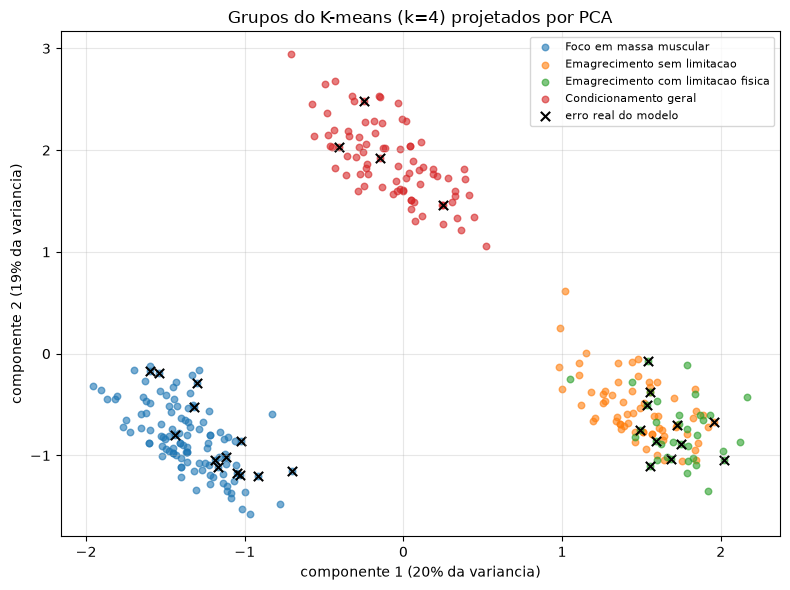

In [18]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(Z)
fig, ax = plt.subplots(figsize=(8, 6))
for g in ordem:
    m = (df['grupo'] == g).values
    ax.scatter(P[m, 0], P[m, 1], s=22, alpha=0.6, label=g)
m_err = (df['erro_real'] == 1).values
ax.scatter(P[m_err, 0], P[m_err, 1], marker='x', color='black', s=45, label='erro real do modelo')
ax.set_xlabel(f'componente 1 ({pca.explained_variance_ratio_[0]:.0%} da variancia)')
ax.set_ylabel(f'componente 2 ({pca.explained_variance_ratio_[1]:.0%} da variancia)')
ax.set_title('Grupos do K-means (k=4) projetados por PCA')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Interpretacao (perguntas de validacao)

**O grupo e grande o suficiente para importar?** Sim, com ressalva. "Emagrecimento com limitacao fisica" tem 36 alunos (12% da base), mas responde por 32% dos erros reais do modelo e por 7 dos 25 falsos negativos reais de Treino D da base (28%). E pequeno em volume e grande em impacto. Na pratica, numa academia, "quer emagrecer mas tem dor no joelho ou na lombar" e um perfil muito comum, nao um caso raro.

**Ele se distingue por mais de uma variavel?** Sim. Alem do objetivo, 100% tem restricao (contra 31% na base), e o grupo tem o menor nivel medio de experiencia e o menor acesso a equipamento entre os quatro. Os outros tres grupos se distinguem basicamente so pelo objetivo, e isso e honesto registrar: eles sao a estrutura "obvia" da base.

**Da para explicar para quem nao viu os dados?** Sim: *"o sistema erra mais com quem quer emagrecer mas tem alguma limitacao fisica, principalmente quem esta comecando. Ele tende a mandar essa pessoa para o circuito de cardio padrao, quando o certo seria um treino adaptado"*.

**Alguma acao pratica diferente faz sentido para ele?** Sim, duas:
1. **Regra de seguranca acima do modelo:** se o aluno tem restricao fisica e e iniciante, recomendar Treino D (ou pedir revisao do professor) independentemente da previsao da arvore. O custo de um falso positivo de D e so eficiencia; o de um falso negativo e risco de lesao (Atividade 10).
2. **Melhoria do modelo para a AS:** criar a variavel de interacao `restricao_e_iniciante` e testar se ela, junto com o `class_weight='balanced'` ja planejado, reduz o erro neste grupo, medindo o resultado por grupo e nao so pela acuracia global.

## 13. Avaliacao honesta do valor da analise

**Sim, agrega valor, mas por um motivo especifico.** Como segmentacao de alunos, o K-means acrescentou pouco: 3 dos 4 grupos so reproduzem a coluna `objetivo`, e o melhor k pela silhueta (k=3) era inteiramente trivial. Ninguem precisa de K-means para saber que existem alunos de hipertrofia, emagrecimento e condicionamento.

O valor esta no **cruzamento com o erro**. Ele transformou o "recall de Treino D de 0,78" das Atividades 10 e 11, que era um numero agregado, em um ponto cego localizado e explicavel: restricao fisica + iniciante fora da hipertrofia. A Atividade 11 apontou o "atalho por idade" em casos isolados do split de teste; aqui, com a base inteira, aparece um padrao mais estrutural. Isso muda o que fazer na AS: em vez de so testar modelos mais complexos, faz sentido atacar uma interacao especifica e medir o erro por grupo.

## 14. Limitacoes

1. **Base sintetica.** Os grupos refletem as regras de `gerar_dataset.py`, e a propria regra tem um ramo especifico "restricao + iniciante -> D". O ponto cego foi encontrado numa logica que nos mesmos escrevemos; com alunos reais nao ha garantia de que o mesmo grupo exista.
2. **Numero de grupos parcialmente arbitrario.** A evidencia estatistica favorecia k=3; o k=4 foi escolhido por um argumento do problema. Com outro k (ex.: 6) o bolsao de condicionamento com restricao poderia aparecer separado, ou o de emagrecimento poderia se diluir.
3. **Variaveis categoricas no K-means.** Objetivo (one-hot) e restricao (0/1) nao sao continuas; a distancia euclidiana entre categorias e uma aproximacao, e as colunas one-hot acabaram dominando a formacao dos grupos. O ordinal 0/1/2 de nivel e equipamento supoe espacamento igual entre as categorias, o que nao e garantido.
4. **Grupo pequeno, conclusao fragil.** 36 alunos e 9 erros reais; um ou dois casos a mais ou a menos mudam bastante a taxa. A verificacao da secao 10 (22 alunos de condicionamento com restricao) e ainda mais fragil.
5. **Validacao sem rotulo.** A silhueta (0,257) e baixa: os grupos nao sao "nuvens" bem separadas, e sim fatias de uma base fortemente categorica. A unica validacao forte que temos e externa (o cruzamento com o erro), nao a qualidade do agrupamento em si.

## 15. Conclusao e itens para o backlog da AS

- Caminho A aplicado com variaveis selecionadas, identificador e rotulo removidos, `StandardScaler`, k escolhido por cotovelo/silhueta + argumento do problema, grupos estaveis (ARI = 1,0 em 10 sementes).
- 4 grupos nomeados; o achado relevante e o grupo **Emagrecimento com limitacao fisica**, com erro de 39% (25% de erro real) contra 17% (9%) na media, concentrado em falsos negativos de Treino D de iniciantes com restricao.
- Novos itens para a AS: (1) testar a feature de interacao `restricao_e_iniciante` + `class_weight='balanced'` e reportar o erro por grupo; (2) avaliar uma regra de seguranca (restricao + iniciante -> Treino D ou revisao humana) sobre a saida do modelo; (3) registrar este ponto cego na analise etica final.